# Baseline Multiple Polynomial Regression Model

In [26]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.preprocessing import PolynomialFeatures
from sklearn.pipeline import make_pipeline

In [27]:
coasters_df = pd.read_csv('coasters_dataset.csv')
coasters_df.head()

,ride_name,park,manufacturer,length_ft,height_ft,speed_mph,inversions,minz_median_g,maxz_median_g,minx_median_g,maxx_median_g,miny_median_g,maxy_median_g,minc_median_g,maxc_median_g
0,Giant Dipper,Belmont Park,Prior & Church,2600.0,73.0,55.0,0,0.0409,4.1443,-1.4110,1.3379,-0.6804,0.9524,0.2018,4.2360
1,Freischütz,Bayern-Park,Maurer Rides GmbH,1584.7,78.7,49.7,4,-0.6222,4.3359,-1.5965,0.5818,-1.0884,1.0752,0.1564,4.4516
2,Abismo,Parque de Atracciones de Madrid,Maurer Rides GmbH,1345.1,160.8,65.2,2,-1.0545,4.0489,-0.8457,1.3601,-0.9926,1.1460,0.0391,4.1736
3,Fridolin's verrückter Zauberexpress,Fantasiana,ART Engineering GmbH,803.8,39.4,31.1,0,0.3886,2.0581,-0.9789,0.2609,-0.8393,0.5829,0.4028,2.2010
4,Stunt Fall,Parque Warner Madrid,Vekoma,1204.1,177.2,61.5,3,-0.4513,5.0310,-0.9638,0.8533,-1.8886,1.4169,0.0080,5.0483


In [28]:
np.random.seed(1)

X = coasters_df.drop(columns=['minz_median_g','maxz_median_g','minx_median_g','maxx_median_g',
                              'miny_median_g','maxy_median_g','minc_median_g','maxc_median_g',
                              'ride_name','park','manufacturer'])
y = coasters_df[['minz_median_g','maxz_median_g','minx_median_g','maxx_median_g',
                 'miny_median_g','maxy_median_g','minc_median_g','maxc_median_g']]

X_train_full,X_test,y_train_full,y_test = train_test_split(
    X,y,test_size=0.20
)
X_train,X_val,y_train,y_val = train_test_split(
    X_train_full,y_train_full,test_size=0.20
)

print(f'Training set size: {len(X_train)} ({len(X_train)/len(X)*100:.2f}%)')
print(f'Validation set size: {len(X_val)} ({len(X_val)/len(X)*100:.2f}%)')
print(f'Test set size: {len(X_test)} ({len(X_test)/len(X)*100:.2f}%)')
print("------------------------------------------")

Training set size: 316 (63.97%)
Validation set size: 79 (15.99%)
Test set size: 99 (20.04%)
------------------------------------------


Loss Value Training Set (MSE): 0.1693908843727881
Loss Value Validation Set (MSE): 0.18165904040940567


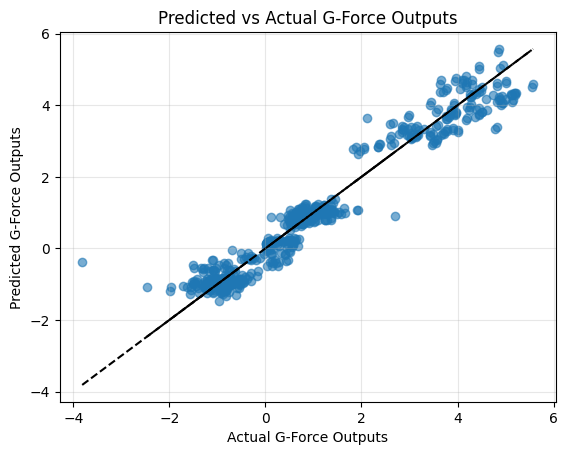

In [29]:

linear_model = LinearRegression()
linear_model.fit(X_train,y_train)

y_pred_val = linear_model.predict(X_val)
y_pred_train = linear_model.predict(X_train)

mse_train = mean_squared_error(y_train,y_pred_train)
mse_val = mean_squared_error(y_val,y_pred_val)

print("Loss Value Training Set (MSE):", mse_train)
print("Loss Value Validation Set (MSE):", mse_val)

plt.scatter(y_val,y_pred_val, c="tab:blue", alpha=0.6)
plt.plot([y_val.min(),y_val.max()],[y_val.min(),y_val.max()],"k--")

plt.ylabel("Predicted G-Force Outputs")
plt.xlabel("Actual G-Force Outputs")
plt.title("Predicted vs Actual G-Force Outputs")
plt.grid(True, alpha=0.3)
plt.show()

1st Degree Model
Loss Value Training Set (MSE): 0.16939088437278804
Loss Value Validation Set (MSE): 0.18165904040940567
------------------------------------------------------------
2nd Degree Model
Loss Value Training Set (MSE): 0.15762526137060756
Loss Value Validation Set (MSE): 0.16948027082337538
------------------------------------------------------------
3rd Degree Model
Loss Value Training Set (MSE): 0.1834317957427215
Loss Value Validation Set (MSE): 0.23129500122100627
------------------------------------------------------------
4th Degree Model
Loss Value Training Set (MSE): 0.2299274850703813
Loss Value Validation Set (MSE): 0.3206272734664589
------------------------------------------------------------


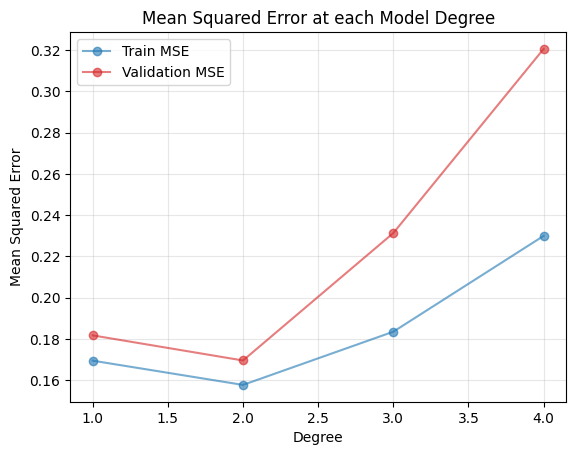

In [30]:
# 1st Degree Model
model = make_pipeline(
    PolynomialFeatures(degree=1, include_bias=False),
    LinearRegression()
)
model.fit(X_train, y_train)
y_pred_val_1 = model.predict(X_val)
y_pred_train_1 = model.predict(X_train)

mse_train = mean_squared_error(y_train,y_pred_train_1)
mse_val = mean_squared_error(y_val,y_pred_val_1)

mse_train_array = np.array(mse_train)
mse_val_array = np.array(mse_val)

print("1st Degree Model")
print("Loss Value Training Set (MSE):", mse_train)
print("Loss Value Validation Set (MSE):", mse_val)
print("------------------------------------------------------------")

# 2nd Degree Model
model = make_pipeline(
    PolynomialFeatures(degree=2, include_bias=False),
    LinearRegression()
)
model.fit(X_train, y_train)
y_pred_val_2 = model.predict(X_val)
y_pred_train_2 = model.predict(X_train)

mse_train = mean_squared_error(y_train,y_pred_train_2)
mse_val = mean_squared_error(y_val,y_pred_val_2)

mse_train_array = np.append(mse_train_array,mse_train)
mse_val_array = np.append(mse_val_array,mse_val)

print("2nd Degree Model")
print("Loss Value Training Set (MSE):", mse_train)
print("Loss Value Validation Set (MSE):", mse_val)
print("------------------------------------------------------------")

# 3rd Degree Model
model = make_pipeline(
    PolynomialFeatures(degree=3, include_bias=False),
    LinearRegression()
)
model.fit(X_train, y_train)
y_pred_val_3 = model.predict(X_val)
y_pred_train_3 = model.predict(X_train)

mse_train = mean_squared_error(y_train,y_pred_train_3)
mse_val = mean_squared_error(y_val,y_pred_val_3)

mse_train_array = np.append(mse_train_array,mse_train)
mse_val_array = np.append(mse_val_array,mse_val)

print("3rd Degree Model")
print("Loss Value Training Set (MSE):", mse_train)
print("Loss Value Validation Set (MSE):", mse_val)
print("------------------------------------------------------------")

# 4th Degree Model
model = make_pipeline(
    PolynomialFeatures(degree=4, include_bias=False),
    LinearRegression()
)
model.fit(X_train, y_train)
y_pred_val_4 = model.predict(X_val)
y_pred_train_4 = model.predict(X_train)

mse_train = mean_squared_error(y_train,y_pred_train_4)
mse_val = mean_squared_error(y_val,y_pred_val_4)

mse_train_array = np.append(mse_train_array,mse_train)
mse_val_array = np.append(mse_val_array,mse_val)

print("4th Degree Model")
print("Loss Value Training Set (MSE):", mse_train)
print("Loss Value Validation Set (MSE):", mse_val)
print("------------------------------------------------------------")

degree = np.array([1,2,3,4])
plt.plot(degree,mse_train_array, label="Train MSE",marker='o',color='tab:blue',alpha=0.6)
plt.plot(degree,mse_val_array, label="Validation MSE",marker='o',color='tab:red',alpha=0.6)

plt.ylabel("Mean Squared Error")
plt.xlabel("Degree")
plt.title("Mean Squared Error at each Model Degree")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

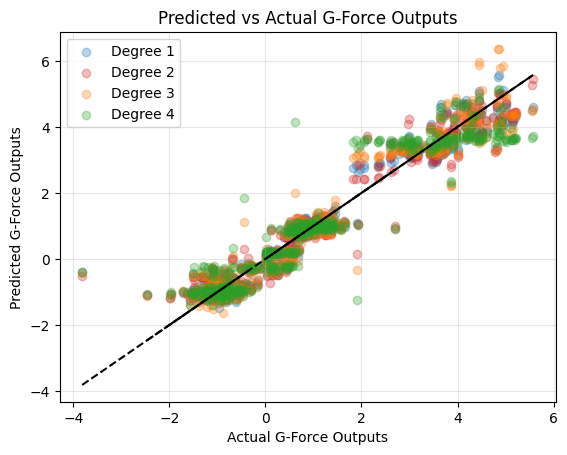

In [33]:
np.random.seed(1)

plt.scatter(y_val,y_pred_val_1, c="tab:blue", alpha=0.3,label='Degree 1')
plt.scatter(y_val,y_pred_val_2, c="tab:red", alpha=0.3,label='Degree 2')
plt.scatter(y_val,y_pred_val_3, c="tab:orange", alpha=0.3,label='Degree 3')
plt.scatter(y_val,y_pred_val_4, c="tab:green", alpha=0.3,label='Degree 4')

plt.plot([y_val.min(),y_val.max()],[y_val.min(),y_val.max()],"k--")

plt.ylabel("Predicted G-Force Outputs")
plt.xlabel("Actual G-Force Outputs")
plt.title("Predicted vs Actual G-Force Outputs")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()